### Part 1: Import Required Libraries


In [1]:
import os
import tensorflow as tf
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from tensorflow.keras import Sequential
from keras.layers import Dense , Flatten , Conv2D , MaxPooling2D , Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator


### Part 2: Define Dataset Paths


In [40]:
train_path = r"C:\Users\FreeComp\OneDrive\Desktop\Route\Assignments\Vegetable Images\Images\train"
test_path = r"C:\Users\FreeComp\OneDrive\Desktop\Route\Assignments\Vegetable Images\Images\test"
valid_path = r"C:\Users\FreeComp\OneDrive\Desktop\Route\Assignments\Vegetable Images\Images\validation"

In [3]:
image_classes = os.listdir(train_path)
image_classes

['Bean',
 'Bitter_Gourd',
 'Bottle_Gourd',
 'Brinjal',
 'Broccoli',
 'Cabbage',
 'Capsicum',
 'Carrot',
 'Cauliflower',
 'Cucumber',
 'Papaya',
 'Potato',
 'Pumpkin',
 'Radish',
 'Tomato']

In [4]:
len(image_classes)

15

In [5]:
fol_img_path = train_path + '/' + image_classes[0]
fol_img_path

'C:\\Users\\FreeComp\\OneDrive\\Desktop\\Route\\Assignments\\Vegetable Images\\train/Bean'

In [6]:
img_in_fol = os.listdir(fol_img_path)
img_in_fol

['0026.jpg',
 '0028.jpg',
 '0029.jpg',
 '0030.jpg',
 '0034.jpg',
 '0035.jpg',
 '0036.jpg',
 '0037.jpg',
 '0039.jpg',
 '0041.jpg',
 '0045.jpg',
 '0047.jpg',
 '0055.jpg',
 '0058.jpg',
 '0061.jpg',
 '0063.jpg',
 '0064.jpg',
 '0065.jpg',
 '0066.jpg',
 '0067.jpg',
 '0068.jpg',
 '0069.jpg',
 '0070.jpg',
 '0071.jpg',
 '0072.jpg',
 '0073.jpg',
 '0074.jpg',
 '0075.jpg',
 '0076.jpg',
 '0077.jpg',
 '0078.jpg',
 '0079.jpg',
 '0080.jpg',
 '0081.jpg',
 '0082.jpg',
 '0083.jpg',
 '0084.jpg',
 '0085.jpg',
 '0086.jpg',
 '0087.jpg',
 '0088.jpg',
 '0089.jpg',
 '0090.jpg',
 '0091.jpg',
 '0092.jpg',
 '0093.jpg',
 '0094.jpg',
 '0095.jpg',
 '0096.jpg',
 '0097.jpg',
 '0098.jpg',
 '0099.jpg',
 '0155.jpg',
 '0156.jpg',
 '0157.jpg',
 '0158.jpg',
 '0159.jpg',
 '0160.jpg',
 '0161.jpg',
 '0162.jpg',
 '0176.jpg',
 '0179.jpg',
 '0181.jpg',
 '0184.jpg',
 '0187.jpg',
 '0189.jpg',
 '0191.jpg',
 '0193.jpg',
 '0194.jpg',
 '0195.jpg',
 '0196.jpg',
 '0214.jpg',
 '0216.jpg',
 '0217.jpg',
 '0218.jpg',
 '0219.jpg',
 '0220.jpg',

In [7]:
from keras.preprocessing import image

In [8]:
def plot_classes (path , image_classes):
    plt.figure (figsize=(12,12))
    for i , cat in enumerate(image_classes):
        fol_img_path = path + '/' + cat
        img_in_fol = os.listdir(fol_img_path)
        f_i = img_in_fol[3]
        fs_i = fol_img_path +'/'+ f_i
        img_ = image.load_img(fs_i)
        img_array = image.img_to_array(img_) / 255
        plt.subplot(4, 4, i+1)
        plt.imshow(img_array)
        plt.title(cat)
        plt.axis('off')
    plt.show()

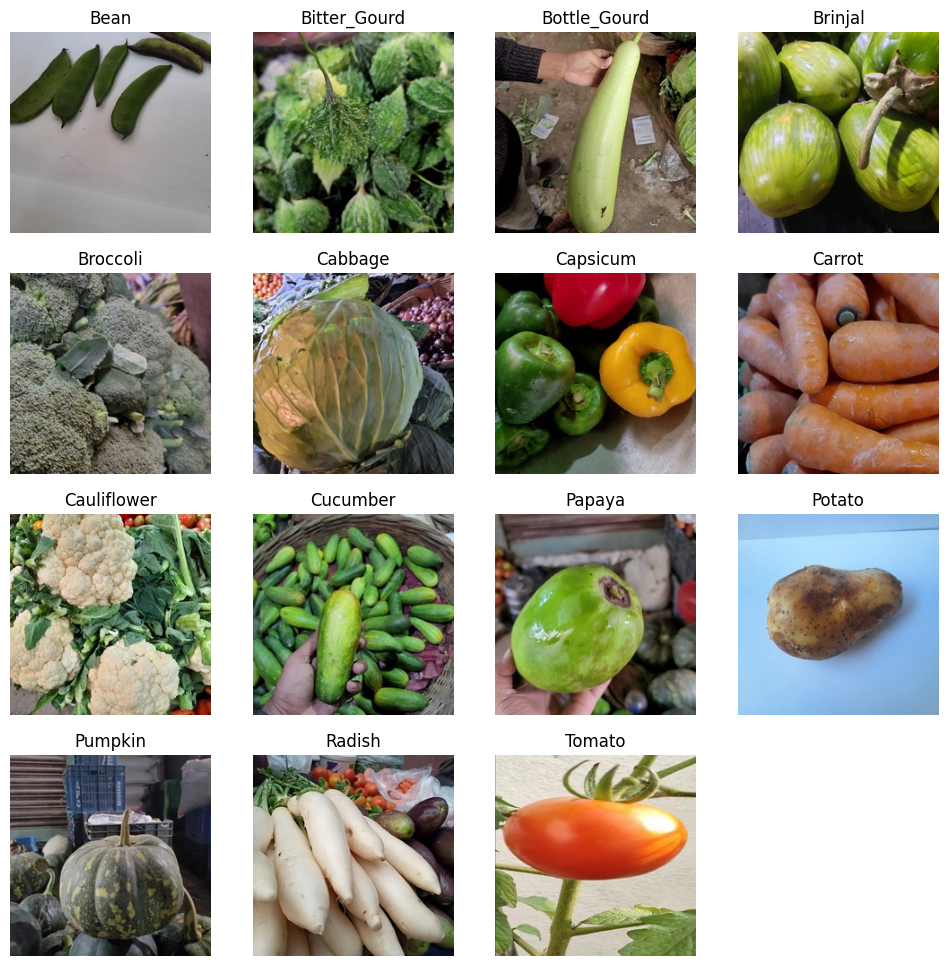

In [9]:
plot_classes(train_path, image_classes)

### Part 3: Count Images in Each Class


In [10]:
def count_img(image_classes):
    counts ={}
    for n in os.listdir(image_classes):
        path_ = os.path.join(image_classes,n)
        image_ = os.listdir(path_)
        counts[n]=len(image_)
    return counts

In [11]:
train_counts = count_img(train_path)
test_counts = count_img(test_path)
val_counts = count_img(valid_path)

In [12]:
print("Train Images:")
print(train_counts)

print("\nTest Images:")
print(test_counts)

print("\nValidation Images:")
print(val_counts)

Train Images:
{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Test Images:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation Images:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


### Part 4: Create a Summary DataFrame


In [13]:
train_df = pd.DataFrame(list(train_counts.items()),columns=['Vegetable', 'Train Count'])
test_df = pd.DataFrame(list(test_counts.items()),columns=['Vegetable', 'Test Count'])
val_df = pd.DataFrame(list(val_counts.items()),columns=['Vegetable', 'Validation Count'])



In [14]:
summary_df = train_df.merge(test_df, on='Vegetable')
summary_df = summary_df.merge(val_df, on='Vegetable')

In [15]:
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


### Part 5: Visualize Class Distribution


<Figure size 1500x600 with 0 Axes>

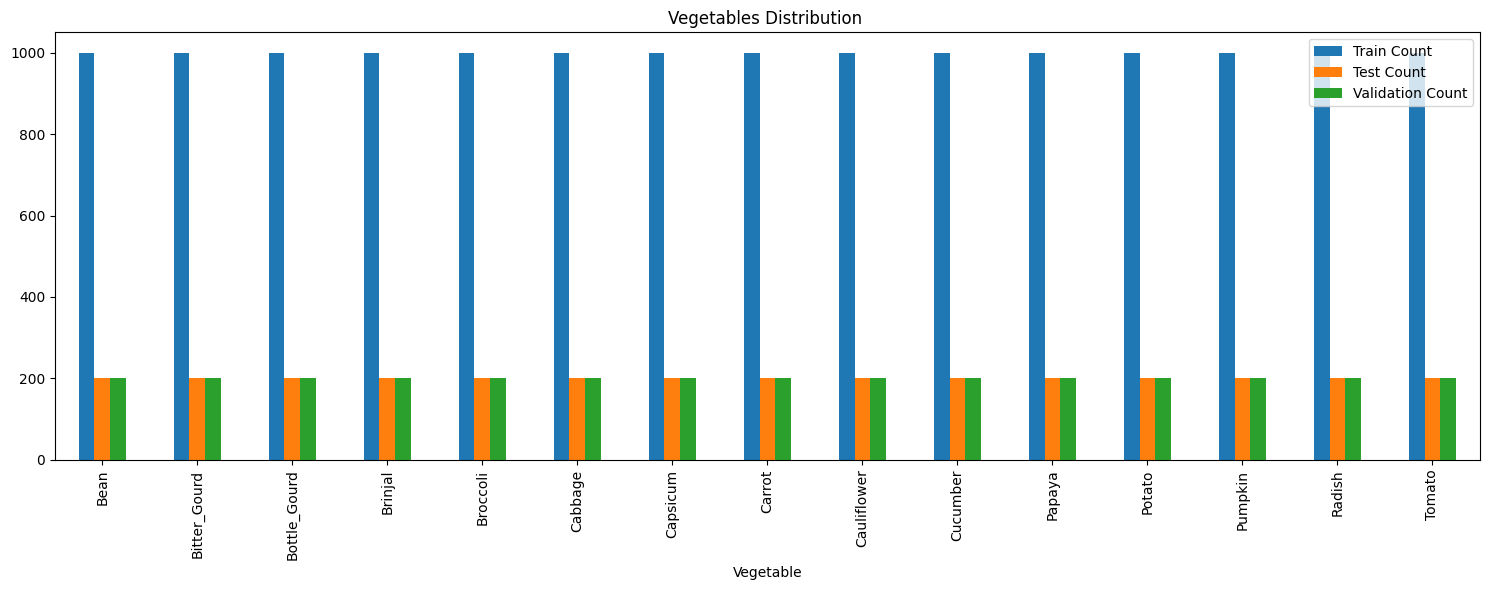

In [16]:
plt.figure(figsize = (15,6))
summary_df.plot(x="Vegetable",y=["Train Count","Test Count","Validation Count"],kind="bar",figsize=(15,6))
plt.title("Vegetables Distribution ")
plt.tight_layout()
plt.show()

### Is the dataset balanced?
Yes, the dataset is balanced because each vegetable class contains the same number of images within each dataset split.

The dataset contains:

1,000 images per class in the Training set.

200 images per class in the Validation set.

200 images per class in the Test set.

Since all 15 classes have equal numbers of images in each split, the dataset is balanced. This helps prevent the model from being biased toward a particular vegetable class during training.


### Part 6: Image Preprocessing and Augmentation


In [18]:
train_data_generator = ImageDataGenerator(rescale=1/255,
                                          rotation_range=30,
                                          width_shift_range=0.2,
                                          height_shift_range=0.2,
                                          shear_range=0.2,
                                          zoom_range=0.2,
                                          horizontal_flip=True,
                                          validation_split=0.2
)

valid_data_generator = ImageDataGenerator(rescale=1/255,validation_split=0.2)
test_data_generator = ImageDataGenerator(rescale=1/255)

### Part 7: Load Images Using flow_from_directory()

In [19]:
train_data = train_data_generator.flow_from_directory(train_path,target_size=(224,224),batch_size = 32,class_mode='categorical',seed = 42)
valid_data = valid_data_generator.flow_from_directory(valid_path,target_size=(224,224),batch_size = 32,class_mode='categorical',seed = 42)
test_data = test_data_generator.flow_from_directory(test_path,target_size=(224,224),batch_size = 32,class_mode='categorical',seed = 42)



Found 15000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


### Part 8: Build the CNN Model


In [20]:
# ANN
cnn_model = Sequential()

# Feature Extraction 
cnn_model.add(Conv2D(filters=32 , kernel_size = 3 , activation = 'relu', input_shape = (224,224,3)))
cnn_model.add(MaxPooling2D(pool_size=(2,2)))

cnn_model.add(Conv2D(filters=64 , kernel_size = 3 , activation = 'relu'))
cnn_model.add(MaxPooling2D(pool_size=(2,2)))

cnn_model.add(Conv2D(filters=128 , kernel_size = 3 , activation = 'relu'))
cnn_model.add(MaxPooling2D(pool_size=(2,2)))


# 1- Flatten layer
cnn_model.add(Flatten())
# 2. Hiddel layers 
cnn_model.add(Dense(512, activation='relu'))
cnn_model.add(Dropout(0.5))



# 3. Output layer
cnn_model.add(Dense(15, activation='softmax'))


### Part 9: Compile the Model and the model summary 


In [21]:
cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

### The Sammary
**1. Number of Convolutional Layers:**

The CNN model contains three Convolutional layers with 32, 64, and 128 filters, respectively. These layers extract important features from images, such as edges, shapes, textures, and more complex patterns.

**2. Purpose of Pooling Layers:**

MaxPooling2D reduces the spatial dimensions of feature maps. It keeps the most important features while reducing computational complexity and helping the model learn efficiently.

**3. Purpose of Dropout:**

Dropout is used to reduce overfitting. During training, it randomly disables 50% of the neurons in the previous layer, which prevents the model from depending too much on specific neurons and improves generalization.

**4. Why Softmax is Used in the Output Layer:**

Softmax converts the output values into probabilities for the 15 vegetable classes. The model predicts the class with the highest probability.

### Part 10: Train the Model


In [24]:
from tensorflow.keras.callbacks import EarlyStopping

In [25]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)


In [27]:
history = cnn_model.fit(train_data,validation_data=valid_data,epochs=20,callbacks=[early_stop])

Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 282s 601ms/step - accuracy: 0.4731 - loss: 1.5489 - val_accuracy: 0.7173 - val_loss: 0.8210
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 213s 454ms/step - accuracy: 0.7098 - loss: 0.8816 - val_accuracy: 0.7710 - val_loss: 0.7361
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 234s 499ms/step - accuracy: 0.7838 - loss: 0.6689 - val_accuracy: 0.8630 - val_loss: 0.4052
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 300s 639ms/step - accuracy: 0.8276 - loss: 0.5384 - val_accuracy: 0.9140 - val_loss: 0.2866
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 212s 452ms/step - accuracy: 0.8483 - loss: 0.4755 - val_accuracy: 0.9273 - val_loss: 0.2498
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 213s 454ms/step - accuracy: 0.8755 - loss: 0.3991 - val_accuracy: 0.9453 - val_loss: 0.1863
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 206s 438ms/step - accuracy: 0.8847 - loss: 0.3617 - val_accuracy: 0.9290 - val_loss: 0.2130
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 204s 434ms/step - accuracy: 0.9023 -

### Why is EarlyStopping Useful ?

EarlyStopping is used to prevent overfitting and avoid unnecessary training.

It monitors the validation loss during training. If the validation loss does not improve for 5 consecutive epochs, training stops automatically.

The parameter restore_best_weights=True restores the model weights from the epoch that achieved the best validation loss.

This helps save training time and keeps the model at its best validation performance.

### Part 11: Evaluate the Model


In [28]:
cnn_model.evaluate(train_data)

469/469 ━━━━━━━━━━━━━━━━━━━━ 163s 347ms/step - accuracy: 0.9673 - loss: 0.1018


[0.1018436923623085, 0.9672666788101196]

In [29]:
cnn_model.evaluate(valid_data)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 78ms/step - accuracy: 0.9783 - loss: 0.0646


[0.06463288515806198, 0.9783333539962769]

In [36]:
train_loss, train_acc = cnn_model.evaluate(train_data)

469/469 ━━━━━━━━━━━━━━━━━━━━ 102s 218ms/step - accuracy: 0.9684 - loss: 0.1059


In [37]:
valid_loss, valid_acc = cnn_model.evaluate(valid_data)

94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.9783 - loss: 0.0646


In [38]:
print("\n--- Model Evaluation Results ---")
print("Training Accuracy: ",train_acc)
print("Validation Accuracy: ",valid_acc)
print("Training Loss: ",train_loss)
print("Validation Loss:",valid_loss)


--- Model Evaluation Results ---
Training Accuracy:  0.9684000015258789
Validation Accuracy:  0.9783333539962769
Training Loss:  0.10593415051698685
Validation Loss: 0.06463289260864258


### Is there a large difference between training accuracy and validation accuracy? What doesthis tell you about overfitting?

The model achieved 96.84% Training Accuracy and 97.83% Validation Accuracy.

The Training Loss was 0.1059, while the Validation Loss was 0.0646.

Overfitting Analysis:

There is no clear sign of overfitting because the validation accuracy is slightly higher than the training accuracy. Also, the validation loss is lower than the training loss.

This means that the model performs well on both training and validation data and can generalize well to new images.

### Part 12: Plot Accuracy and Loss Curves


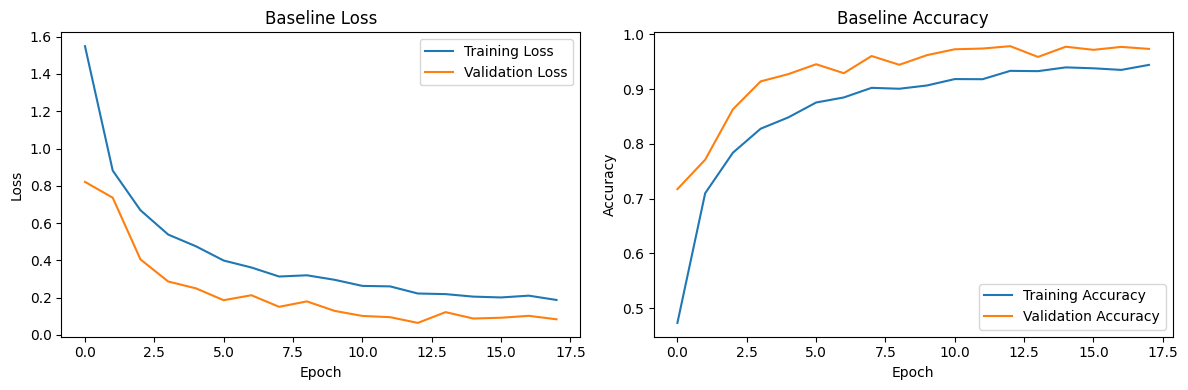

In [39]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Baseline Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Baseline Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()